In [19]:
# ═══ cellule 1 ═══ imports, configuration, helpers
from __future__ import annotations

import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from hydra import compose, initialize_config_dir
from hydra.core.global_hydra import GlobalHydra
from omegaconf import OmegaConf
from torch.utils.data import DataLoader, TensorDataset

from src.config import PROJ_ROOT, RESULT_DIR
from src.detector.subjectivity_aware_generation_estimator.features.feature_spec import SPECS, get_spec
from src.detector.subjectivity_aware_generation_estimator.features.tensor_builder import (
    build_dataset, fit_context,
)
from src.detector.subjectivity_aware_generation_estimator.model.SimpleGRU import SimpleGRU
from src.detector.subjectivity_aware_generation_estimator.training.gru_train import (
    prepare_data, train_model,
)
from src.detector.subjectivity_aware_generation_estimator.xai.category_permutation import (
    ALL, fit_marginals, resample_category,
)
from src.detector.subjectivity_aware_generation_estimator.xai.direction import (
    convert_toward, subjectivity_pools,
)
from src.detector.subjectivity_aware_generation_estimator.xai.metrics import detection_metrics
from src.detector.subjectivity_aware_generation_estimator.xai.order_perturbation import (
    reverse_within_review, shuffle_within_review,
)
from src.detector.subjectivity_aware_generation_estimator.xai.reporting import print_table
from src.detector.subjectivity_aware_generation_estimator.xai.results_store import (
    PROTO_PAIRED, load, record_metrics, record_run, summary,
)
from src.detector.subjectivity_aware_generation_estimator.xai.sources import SOURCES, bibliography

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", None)

CONF_DIR = str(PROJ_ROOT / "conf")
OUT_DIR = Path(RESULT_DIR) / "xai" / "v3"
OUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda:0"
EXPERIMENT = "train/train_sage_gru_v3"
REFERENCE = "v3_multi_novalid"
METRICS = ["auc", "acc", "tpr@fpr1", "tpr@fpr0_1"]
SEEDS = (0, 1, 2, 3, 4)
N_PERM = 10  # répétitions pour les perturbations (modèle figé)
REUSE = True  # relit les CSV existants au lieu de recalculer


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def load_cfg(spec_name: str = REFERENCE, seed: int = 0):
    """Compose la config hors CLI. set_struct(False) contourne le mode struct,
    qui refuse l'ajout de clés absentes du groupe (seed, feature_spec)."""
    GlobalHydra.instance().clear()
    with initialize_config_dir(config_dir=CONF_DIR, version_base="1.3"):
        cfg = compose(config_name="train", overrides=[f"+experiment={EXPERIMENT}"])
    OmegaConf.set_struct(cfg, False)
    cfg.training.model.seed = seed
    cfg.training.model.feature_spec = spec_name
    cfg.hardware.device = DEVICE
    OmegaConf.set_struct(cfg, True)
    return cfg


@torch.no_grad()
def predict(model, X, L, device=DEVICE, batch_size=512) -> np.ndarray:
    model.eval()
    ps = []
    for xb, lb in DataLoader(TensorDataset(X, L), batch_size=batch_size, shuffle=False):
        ps.append(torch.sigmoid(model(xb.to(device), lb)).cpu().numpy())
    return np.concatenate(ps).ravel()


def cached(path: Path, compute):
    if REUSE and path.exists():
        print(f"📦 {path.name}")
        return pd.read_csv(path)
    df = compute()
    df.to_csv(path, index=False)
    return df


def compare(runs: pd.DataFrame, reference: str, metrics=METRICS) -> pd.DataFrame:
    """Moyenne, écart-type, delta contre la référence et erreur-type de la différence.
    Un delta sous deux erreurs-types n'est pas interprétable."""
    agg = runs.groupby("condition")[metrics].agg(["mean", "std"])
    agg.columns = [f"{a}_{b}" for a, b in agg.columns]
    agg["n"] = runs.groupby("condition").size()
    ref = agg.loc[reference]
    for m in metrics:
        agg[f"delta_{m}"] = ref[f"{m}_mean"] - agg[f"{m}_mean"]
        agg[f"se_{m}"] = np.sqrt(agg[f"{m}_std"] ** 2 / agg["n"] + ref[f"{m}_std"] ** 2 / ref["n"])
    agg["significatif"] = np.where(agg["delta_auc"].abs() > 2 * agg["se_auc"], "oui", "non")
    return agg.sort_values("delta_auc", ascending=False)


print(f"torch {torch.__version__} | device {DEVICE} | REUSE={REUSE} | sorties {OUT_DIR}")

torch 2.11.0+cu126 | device cuda:0 | REUSE=True | sorties /data2/cyaiche/cache_dir/results/xai/v3


In [20]:
# ═══ cellule 2 ═══ inventaire des specs v3, contrôle du partage de cache
V3_SPECS = sorted(s for s in SPECS if s.startswith("v3_"))
MERGE_SPECS = [REFERENCE] + sorted(s for s in SPECS if s.startswith("v3_merge_"))
BLOCK_SPECS = [REFERENCE, "v3_cat_only", "v3_subj_only"]

rows = []
for name in V3_SPECS:
    sp = get_spec(name)
    merged = next((g.merge for g in sp.groups if g.merge), ())
    rows.append({"spec": name, "input_dim": sp.input_dim, "hash": sp.hash(),
                 "groupes": ", ".join(sp.players), "fusion": ", ".join(merged) or "—",
                 "seg_key": str(sp.segmentation_key())})
inventaire = pd.DataFrame(rows)
print_table(inventaire[["spec", "input_dim", "groupes", "fusion", "hash"]],
            title="Specs v3", index=False)

assert inventaire["hash"].is_unique, "collision de hash entre specs"
assert inventaire["seg_key"].nunique() == 1, "clés de segmentation divergentes -> resegmentation"
print("✅ hashes distincts, segmentation partagée")

== Specs v3 ==
               spec  input_dim   groupes     fusion         hash
        v3_cat_only          5       cat          — 1ea6a4bf8a51
v3_merge_expressive          6 cat, subj Expressive fa747af27cfc
   v3_merge_neither          6 cat, subj    Neither 29fd51e5db82
  v3_merge_question          6 cat, subj   Question 374ac6133558
v3_merge_suggestion          6 cat, subj Suggestion 3213697d4296
   v3_multi_novalid          6 cat, subj          — 77627d888210
       v3_subj_only          1      subj          — ec17e4084d42

✅ hashes distincts, segmentation partagée


In [21]:
# ═══ cellule 3 ═══ segmentation + appariement, une seule fois
cfg = load_cfg(REFERENCE, seed=0)
PARAMS_MODEL = OmegaConf.to_container(cfg.training.model.params_model, resolve=True)
PARAMS_MODEL.pop("n_features", None)  # dérivé de spec.input_dim
PARAMS_TRAIN = OmegaConf.to_container(cfg.training.model.params_training, resolve=True)
BATCH = int(cfg.training.model["batch_size"])

_d = prepare_data(cfg)
DF_TRAIN, DF_VAL = _d["df_train"], _d["df_val"]
N_TRAIN, N_VAL = int(len(_d["Ytr"])), int(len(_d["Yva"]))

print(f"\nrelectures  train {N_TRAIN}  val {N_VAL}  part MGT val {_d['Yva'].float().mean():.3f}")
print(f"phrases     train {len(DF_TRAIN)}  val {len(DF_VAL)}")
print(f"longueurs val : médiane {_d['Lva'].median().item():.0f}  max {_d['Lva'].max().item()}")
print(f"params_model {PARAMS_MODEL} | params_training {PARAMS_TRAIN} | batch {BATCH}")

Loading APRDB dataset from IntelLabs/AI-Peer-Review-Detection-Benchmark with config: {'name': 'aprdb', 'description': 'AI Peer Review Detection Benchmark, test subset, binaire mgt/hwt', 'conference': None, 'date': None, 'keep_meta': True, 'subset_size': 10000, 'split': 'calibration', 'with_pdf': False, 'seed': 0}
📦 Loading dataset from cache: /data2/cyaiche/cache_dir/dataset_cache/dataset_4fbe88291ebaf69cc7d4bd78214b8d51.pt
📦 Loading data from cache: /data2/cyaiche/cache_dir/results/implicite_segmentation/4fbe88291ebaf69cc7d4bd78214b8d51_eaf4e799/sentences_degrees_final.csv
appariement : 3017 paires | HWT écartés 0 | versions MGT écartées 1983
générateurs retenus : {'llama': 638, 'qwen': 627, 'gemini': 613, 'claude': 580, 'gpt4o': 559}
Loading APRDB dataset from IntelLabs/AI-Peer-Review-Detection-Benchmark with config: {'name': 'aprdb', 'description': 'AI Peer Review Detection Benchmark, test subset, binaire mgt/hwt', 'conference': None, 'date': None, 'keep_meta': True, 'subset_size': 

In [22]:
# ═══ cellule 4 ═══ runner générique : une condition = (spec, transform_train, transform_test)
def run_condition(spec_name: str, seed: int, transform_train=None, transform_test=None,
                  verbose: bool = False) -> tuple[dict, SimpleGRU, dict]:
    """Entraîne un GRU sur une condition et évalue sur le test transformé de même façon.

    Les transformations s'appliquent au DataFrame de phrases, en amont de build_dataset :
    la construction des features reste strictement celle de l'entraînement de référence.
    """
    spec = get_spec(spec_name)
    rng = np.random.default_rng(1000 + seed)

    dtr = transform_train(DF_TRAIN, rng) if transform_train else DF_TRAIN
    dte = transform_test(DF_VAL, rng) if transform_test else DF_VAL

    ctx = fit_context(dtr, spec)
    Xtr, Ltr, Ytr, _ = build_dataset(dtr, spec, ctx)
    Xte, Lte, Yte, _ = build_dataset(dte, spec, ctx)
    if Xtr.shape[-1] != spec.input_dim or Xte.shape[-1] != spec.input_dim:
        raise ValueError(f"dimension inattendue pour {spec_name}")

    set_seed(seed)  # après les transformations, qui consomment de l'aléatoire
    model = SimpleGRU(n_features=spec.input_dim, **PARAMS_MODEL)
    train_dl = DataLoader(TensorDataset(Xtr, Ltr, Ytr), batch_size=BATCH, shuffle=True)

    if verbose:
        train_model(model, train_dl, **PARAMS_TRAIN, device=DEVICE)
    else:
        import contextlib, io
        with contextlib.redirect_stdout(io.StringIO()):
            train_model(model, train_dl, **PARAMS_TRAIN, device=DEVICE)

    y = Yte.numpy()
    p = predict(model, Xte, Lte)
    return detection_metrics(y, p, threshold=0.5), model, {"ctx": ctx, "y": y, "p": p}


def run_grid(conditions: dict, seeds=SEEDS) -> pd.DataFrame:
    """conditions : {nom -> (spec_name, transform_train, transform_test)}"""
    rows = []
    for name, (spec_name, ttr, tte) in conditions.items():
        for seed in seeds:
            m, _, _ = run_condition(spec_name, seed, ttr, tte)
            rows.append({"condition": name, "spec": spec_name, "seed": seed, **m})
            print(f"  {name:24s} seed {seed}  AUC {m['auc']:.4f}  TPR@1% {m['tpr@fpr1']:.4f}")
    return pd.DataFrame(rows)

In [23]:
# ═══ cellule 5 ═══ AXE 1 — blocs de features (LOFO)
# Méthode : retrait du bloc puis réentraînement. Interprétation conditionnelle,
# à l'inverse de la PFI qui est marginale. [molnar_lofo, lei2018]
COND_BLOCKS = {
    "reference": (REFERENCE, None, None),
    "categories_seules": ("v3_cat_only", None, None),
    "subjectivite_seule": ("v3_subj_only", None, None),
}

runs_blocks = cached(OUT_DIR / "axe1_blocs.csv", lambda: run_grid(COND_BLOCKS))
print_table(compare(runs_blocks, "reference")[
                ["auc_mean", "auc_std", "delta_auc", "se_auc", "significatif",
                 "delta_acc", "delta_tpr@fpr1", "se_tpr@fpr1", "delta_tpr@fpr0_1"]],
            title="AXE 1 — LOFO par bloc de features")


📦 axe1_blocs.csv
== AXE 1 — LOFO par bloc de features ==
                    auc_mean  auc_std  delta_auc  se_auc significatif  delta_acc  delta_tpr@fpr1  se_tpr@fpr1  delta_tpr@fpr0_1
condition                                                                                                                      
subjectivite_seule    0.8632   0.0078     0.0934  0.0037          oui     0.1067          0.2708       0.0073            0.1417
categories_seules     0.9268   0.0033     0.0298  0.0019          oui     0.0467          0.0573       0.0143            0.0887
reference             0.9566   0.0027     0.0000  0.0017          non     0.0000          0.0000       0.0067            0.0000



In [24]:
# ═══ cellule 6 ═══ AXE 2 — temporalité
# Le mélange intra-relecture conserve strictement la composition : seule
# l'information d'ordre est détruite. Seule la condition train+test mesure
# l'information d'ordre ; les autres isolent le biais de récence. [molnar_lofo]
_shuf = lambda df, rng: shuffle_within_review(df, rng)
_rev = lambda df, rng: reverse_within_review(df, rng)

COND_ORDER = {
    "ordre_intact": (REFERENCE, None, None),
    "melange_train_et_test": (REFERENCE, _shuf, _shuf),
    "melange_train_seul": (REFERENCE, _shuf, None),
    "melange_test_seul": (REFERENCE, None, _shuf),
    "inversion_test_seul": (REFERENCE, None, _rev),
}

runs_order = cached(OUT_DIR / "axe2_ordre.csv", lambda: run_grid(COND_ORDER))
print_table(compare(runs_order, "ordre_intact")[
                ["auc_mean", "auc_std", "delta_auc", "se_auc", "significatif",
                 "delta_acc", "delta_tpr@fpr1", "se_tpr@fpr1"]],
            title="AXE 2 — temporalité")

📦 axe2_ordre.csv
== AXE 2 — temporalité ==
                       auc_mean  auc_std  delta_auc  se_auc significatif  delta_acc  delta_tpr@fpr1  se_tpr@fpr1
condition                                                                                                       
melange_test_seul        0.8254   0.0079     0.1312  0.0038          oui     0.1556          0.2538       0.0089
inversion_test_seul      0.8666   0.0087     0.0900  0.0041          oui     0.1239          0.2560       0.0102
melange_train_seul       0.8906   0.0142     0.0660  0.0064          oui     0.0789          0.1560       0.0281
melange_train_et_test    0.9079   0.0111     0.0487  0.0051          oui     0.0635          0.1774       0.0267
ordre_intact             0.9566   0.0027     0.0000  0.0017          non     0.0000          0.0000       0.0067



In [25]:
# ═══ cellule 7 ═══ AXE 3a — fusion de catégories (LOFO)
# Fusion et non suppression : retirer une colonne du one-hot laisserait un vecteur
# nul identifiable. Positions conservées, capacité constante. [molnar_lofo]
COND_MERGE = {s.replace("v3_merge_", "fusion_").replace("v3_multi_novalid", "reference"):
                  (s, None, None) for s in MERGE_SPECS}

runs_merge = cached(OUT_DIR / "axe3_fusion.csv", lambda: run_grid(COND_MERGE))
print_table(compare(runs_merge, "reference")[
                ["auc_mean", "auc_std", "delta_auc", "se_auc", "significatif",
                 "delta_acc", "delta_tpr@fpr1", "se_tpr@fpr1", "delta_tpr@fpr0_1"]],
            title="AXE 3a — LOFO par fusion de catégorie")

📦 axe3_fusion.csv
== AXE 3a — LOFO par fusion de catégorie ==
                   auc_mean  auc_std  delta_auc  se_auc significatif  delta_acc  delta_tpr@fpr1  se_tpr@fpr1  delta_tpr@fpr0_1
condition                                                                                                                     
fusion_suggestion    0.9294   0.0108     0.0272  0.0050          oui     0.0376          0.1068       0.0167            0.0392
fusion_question      0.9321   0.0041     0.0245  0.0022          oui     0.0353          0.0519       0.0068            0.0194
fusion_neither       0.9473   0.0044     0.0093  0.0023          oui     0.0125          0.0660       0.0187            0.0766
fusion_expressive    0.9495   0.0060     0.0071  0.0030          oui     0.0109          0.0198       0.0129           -0.0460
reference            0.9566   0.0027     0.0000  0.0017          non     0.0000          0.0000       0.0067            0.0000



In [26]:
# ═══ cellule 7b ═══ AXE 3a' — catégorie rendue non informative (permutation + réapprentissage)
from src.detector.subjectivity_aware_generation_estimator.xai.lofo_resample import noise_conditions

SPEC_REF = get_spec(REFERENCE)

COND_NOISE = noise_conditions(SPEC_REF, REFERENCE, include_all=True)
runs_noise = cached(OUT_DIR / "axe3_bruit.csv", lambda: run_grid(COND_NOISE))

print_table(compare(runs_noise, "reference")[
                ["auc_mean", "auc_std", "delta_auc", "se_auc", "significatif",
                 "delta_acc", "delta_tpr@fpr1", "se_tpr@fpr1"]],
            title="AXE 3a' — LOFO par rééchantillonnage (marginales conservées)")

📦 axe3_bruit.csv
== AXE 3a' — LOFO par rééchantillonnage (marginales conservées) ==
                  auc_mean  auc_std  delta_auc  se_auc significatif  delta_acc  delta_tpr@fpr1  se_tpr@fpr1
condition                                                                                                  
bruit_TOUTES        0.8355   0.0104     0.1211  0.0048          oui     0.1299          0.3365       0.0055
bruit_Assertion     0.8404   0.0089     0.1162  0.0042          oui     0.1261          0.3292       0.0062
bruit_Neither       0.9205   0.0070     0.0362  0.0034          oui     0.0448          0.2218       0.0233
bruit_Question      0.9291   0.0026     0.0275  0.0017          oui     0.0378          0.0874       0.0101
bruit_Suggestion    0.9325   0.0132     0.0241  0.0060          oui     0.0335          0.1279       0.0151
bruit_Expressive    0.9511   0.0059     0.0055  0.0029          non     0.0075          0.0317       0.0157
reference           0.9566   0.0027     0.0000  0.00

In [27]:
# ═══ cellule 7c ═══ fusion vs rééchantillonnage : les deux opérationnalisations concordent-elles ?
_fus = (compare(runs_merge, "reference")[["delta_auc", "se_auc", "delta_tpr@fpr1"]]
        .rename(columns=lambda c: c + "_fusion"))
_fus.index = [i.replace("fusion_", "").capitalize() for i in _fus.index]

_bru = (compare(runs_noise, "reference")[["delta_auc", "se_auc", "delta_tpr@fpr1"]]
        .rename(columns=lambda c: c + "_bruit"))
_bru.index = [i.replace("bruit_", "").capitalize() for i in _bru.index]

comp = _fus.join(_bru, how="inner")
comp["ecart"] = comp["delta_auc_bruit"] - comp["delta_auc_fusion"]
comp["se_ecart"] = np.sqrt(comp["se_auc_fusion"] ** 2 + comp["se_auc_bruit"] ** 2)
comp["concordant"] = np.where(comp["ecart"].abs() < 2 * comp["se_ecart"], "oui", "NON")
print_table(comp.sort_values("delta_auc_bruit", ascending=False),
            title="Fusion vs rééchantillonnage — concordance des deux opérationnalisations")

== Fusion vs rééchantillonnage — concordance des deux opérationnalisations ==
            delta_auc_fusion  se_auc_fusion  delta_tpr@fpr1_fusion  delta_auc_bruit  se_auc_bruit  delta_tpr@fpr1_bruit   ecart  se_ecart concordant
Neither               0.0093         0.0023                 0.0660           0.0362        0.0034                0.2218  0.0269    0.0041        NON
Question              0.0245         0.0022                 0.0519           0.0275        0.0017                0.0874  0.0030    0.0028        oui
Suggestion            0.0272         0.0050                 0.1068           0.0241        0.0060                0.1279 -0.0031    0.0078        oui
Expressive            0.0071         0.0030                 0.0198           0.0055        0.0029                0.0317 -0.0016    0.0041        oui
Reference             0.0000         0.0017                 0.0000           0.0000        0.0017                0.0000  0.0000    0.0025        oui



In [28]:
# ═══ cellule 8 ═══ AXE 3b — PFI par catégorie (modèle figé)
# Rééchantillonnage bidirectionnel à marginales conservées : le lien catégorie-étiquette
# est rompu sans créer d'instances irréalistes. [molnar_pfi, fisher2019, breiman2001]
_, MODEL_REF, INFO_REF = run_condition(REFERENCE, seed=0, verbose=True)
CTX_REF = INFO_REF["ctx"]
BASE = detection_metrics(INFO_REF["y"], INFO_REF["p"], threshold=0.5)
print("référence : " + "  ".join(f"{k} {v:.4f}" for k, v in BASE.items()))


def _pfi_categories() -> pd.DataFrame:
    marg = fit_marginals(DF_VAL, list(SPEC_REF.label_cats), list(SPEC_REF.subj_category))
    print({c: round(p, 3) for c, p in marg.p.items()})
    rng = np.random.default_rng(0)
    rows = []
    for target in [*SPEC_REF.label_cats, ALL]:
        for r in range(N_PERM):
            dfp = resample_category(DF_VAL, target, marg, rng)
            Xp, Lp, Yp, _ = build_dataset(dfp, SPEC_REF, CTX_REF)
            m = detection_metrics(Yp.numpy(), predict(MODEL_REF, Xp, Lp), threshold=0.5)
            # dose : fraction de phrases effectivement modifiées, pour comparer
            # des catégories de prévalences très différentes
            dose = float((dfp["rule_based_SA-label"].to_numpy()
                          != DF_VAL["rule_based_SA-label"].to_numpy()).mean())
            rows.append({"condition": target, "repetition": r, "dose": dose,
                         **{f"delta_{k}": BASE[k] - v for k, v in m.items()}, **m})
        last = pd.DataFrame(rows[-N_PERM:])
        print(f"  {target:12s} dAUC {last['delta_auc'].mean():+.4f}  dose {last['dose'].mean():.3f}")
    return pd.DataFrame(rows)


runs_pfi = cached(OUT_DIR / "axe3_pfi.csv", _pfi_categories)

pfi_sum = runs_pfi.groupby("condition").agg(
    delta_auc=("delta_auc", "mean"), delta_auc_std=("delta_auc", "std"),
    delta_tpr1=("delta_tpr@fpr1", "mean"), dose=("dose", "mean"))
pfi_sum["dauc_par_dose"] = pfi_sum["delta_auc"] / pfi_sum["dose"].replace(0, np.nan)
print_table(pfi_sum.sort_values("dauc_par_dose", ascending=False),
            title="AXE 3b — PFI par catégorie, normalisée par la dose")

Train on device : cuda:0
epoch  0  loss 0.6780
epoch  3  loss 0.3002
epoch  6  loss 0.2221
epoch  9  loss 0.1958
epoch 12  loss 0.1837
epoch 15  loss 0.1703
epoch 18  loss 0.1647
epoch 21  loss 0.1597
epoch 24  loss 0.1554
epoch 27  loss 0.1520
epoch 29  loss 0.1505
référence : auc 0.9549  acc 0.8806  tpr@fpr1 0.4588  acc@fpr1 0.7245  fpr_eff@fpr1 0.0098  tpr@fpr0_1 0.2084  acc@fpr0_1 0.6037  fpr_eff@fpr0_1 0.0009
📦 axe3_pfi.csv
== AXE 3b — PFI par catégorie, normalisée par la dose ==
            delta_auc  delta_auc_std  delta_tpr1   dose  dauc_par_dose
condition                                                             
Expressive     0.0411         0.0014      0.0740 0.0234         1.7552
Question       0.1658         0.0040      0.3082 0.1248         1.3285
__ALL__        0.3509         0.0037      0.4159 0.3607         0.9728
Assertion      0.3157         0.0035      0.4075 0.3312         0.9530
Suggestion     0.0701         0.0020      0.1666 0.0757         0.9263
Neither      

In [29]:
# ═══ cellule 8 ═══ AXE 1bis — PFI par blocs (modèle figé)
# Contrepartie marginale du LOFO : le modèle n'est pas réentraîné, on mesure ce sur
# quoi CE GRU s'appuie, là où le LOFO mesure ce que l'information vaut en autonomie.
# [molnar_pfi, fisher2019, breiman2001]
from src.detector.subjectivity_aware_generation_estimator.xai.category_permutation import (
    resample_subjectivity,
)

SPEC_REF = get_spec(REFERENCE)
_, MODEL_REF, INFO_REF = run_condition(REFERENCE, seed=0, verbose=True)
CTX_REF = INFO_REF["ctx"]
BASE = detection_metrics(INFO_REF["y"], INFO_REF["p"], threshold=0.5)
print("référence : " + "  ".join(f"{k} {v:.4f}" for k, v in BASE.items()))


def _pfi_blocks() -> pd.DataFrame:
    marg = fit_marginals(DF_VAL, list(SPEC_REF.label_cats), list(SPEC_REF.subj_category))
    rng = np.random.default_rng(0)

    perturbations = {
        # bloc catégories : rééchantillonnage complet du one-hot, marginales conservées
        "bloc_categories": lambda df, g: resample_category(df, ALL, marg, g),
        # bloc subjectivité : scores rééchantillonnés parmi toutes les phrases scorées,
        # catégories inchangées
        "bloc_subjectivite": lambda df, g: resample_subjectivity(df, marg, g,
                                                                 within_category=False),
    }

    rows = [{"condition": "reference", "repetition": r, **BASE} for r in range(N_PERM)]
    for name, fn in perturbations.items():
        for r in range(N_PERM):
            dfp = fn(DF_VAL, rng)
            Xp, Lp, Yp, _ = build_dataset(dfp, SPEC_REF, CTX_REF)
            m = detection_metrics(Yp.numpy(), predict(MODEL_REF, Xp, Lp), threshold=0.5)
            rows.append({"condition": name, "repetition": r, **m})
        last = pd.DataFrame(rows[-N_PERM:])
        print(f"  {name:20s} AUC {last['auc'].mean():.4f}  "
              f"dAUC {BASE['auc'] - last['auc'].mean():+.4f}")
    return pd.DataFrame(rows)


runs_pfi_blocks = cached(OUT_DIR / "axe1_pfi_blocs.csv", _pfi_blocks)
print_table(compare(runs_pfi_blocks, "reference")[
                ["auc_mean", "auc_std", "delta_auc", "se_auc", "delta_tpr@fpr1"]],
            title="AXE 1bis — PFI par bloc (modèle figé)")

Train on device : cuda:0
epoch  0  loss 0.6780
epoch  3  loss 0.3002
epoch  6  loss 0.2221
epoch  9  loss 0.1958
epoch 12  loss 0.1837
epoch 15  loss 0.1703
epoch 18  loss 0.1647
epoch 21  loss 0.1597
epoch 24  loss 0.1554
epoch 27  loss 0.1520
epoch 29  loss 0.1505
référence : auc 0.9549  acc 0.8806  tpr@fpr1 0.4588  acc@fpr1 0.7245  fpr_eff@fpr1 0.0098  tpr@fpr0_1 0.2084  acc@fpr0_1 0.6037  fpr_eff@fpr0_1 0.0009
📦 axe1_pfi_blocs.csv
== AXE 1bis — PFI par bloc (modèle figé) ==
                   auc_mean  auc_std  delta_auc  se_auc  delta_tpr@fpr1
condition                                                              
bloc_categories      0.6009   0.0036     0.3540  0.0011          0.4168
bloc_subjectivite    0.8596   0.0027     0.0953  0.0009          0.2826
reference            0.9549   0.0000     0.0000  0.0000          0.0000



In [30]:
# ═══ cellule 9 ═══ AXE 3c — direction de l'effet (intervention dirigée)
# Comble une limite explicite de la PFI, qui donne l'ampleur et non le sens. [molnar_pfi]
FRACTIONS = (0.10, 0.25)


def _direction() -> pd.DataFrame:
    scored = tuple(SPEC_REF.subj_category)
    pools = subjectivity_pools(DF_VAL, scored)
    rng = np.random.default_rng(0)
    p_ref = float(INFO_REF["p"].mean())
    print(f"p_mgt moyen de référence : {p_ref:.4f}")
    rows = []
    for target in SPEC_REF.label_cats:
        for frac in FRACTIONS:
            for r in range(5):
                dfc = convert_toward(DF_VAL, target, frac, scored, pools, rng)
                Xc, Lc, _, _ = build_dataset(dfc, SPEC_REF, CTX_REF)
                pm = float(predict(MODEL_REF, Xc, Lc).mean())
                rows.append({"condition": f"{target}@{frac:.2f}", "vers": target,
                             "fraction_convertie": frac, "repetition": r,
                             "p_mgt_moyen": pm, "variation": pm - p_ref,
                             "p_mgt_reference": p_ref})
    return pd.DataFrame(rows)


runs_dir = cached(OUT_DIR / "axe3_direction.csv", _direction)
P_REF = float(runs_dir["p_mgt_reference"].iloc[0])

dir_sum = (runs_dir.groupby(["vers", "fraction_convertie"])
           .agg(p_mgt_moyen=("p_mgt_moyen", "mean"), variation=("variation", "mean"),
                ecart_type=("variation", "std")).reset_index())
dir_sum["sens"] = np.where(dir_sum["variation"] > 0, "vers MGT", "vers HWT")
print_table(dir_sum.sort_values(["vers", "fraction_convertie"]),
            title=f"AXE 3c — direction (référence p_mgt = {P_REF:.4f})", index=False)

📦 axe3_direction.csv
== AXE 3c — direction (référence p_mgt = 0.4856) ==
      vers  fraction_convertie  p_mgt_moyen  variation  ecart_type     sens
 Assertion              0.1000       0.4840    -0.0016      0.0004 vers HWT
 Assertion              0.2500       0.4866     0.0010      0.0012 vers MGT
Expressive              0.1000       0.1271    -0.3586      0.0021 vers HWT
Expressive              0.2500       0.0160    -0.4696      0.0006 vers HWT
   Neither              0.1000       0.3294    -0.1562      0.0027 vers HWT
   Neither              0.2500       0.1439    -0.3417      0.0019 vers HWT
  Question              0.1000       0.1801    -0.3055      0.0018 vers HWT
  Question              0.2500       0.0412    -0.4444      0.0006 vers HWT
Suggestion              0.1000       0.2021    -0.2835      0.0023 vers HWT
Suggestion              0.2500       0.0401    -0.4455      0.0016 vers HWT



In [31]:
# ═══ cellule 10 ═══ enregistrement dans le magasin
CTX_RUN = {"n_reviews_train": N_TRAIN, "n_reviews_val": N_VAL, "device": DEVICE,
           "epochs": PARAMS_TRAIN.get("epochs"), "lr": PARAMS_TRAIN.get("lr")}

_to_record = [
    ("lofo_blocs", runs_blocks, METRICS, "seed",
     "Retrait du groupe entier (v3_cat_only, v3_subj_only), hyperparamètres figés."),
    ("ordre_lofo", runs_order, METRICS, "seed",
     "Mélange intra-relecture ; composition conservée, ordre détruit."),
    ("lofo_fusion_categories", runs_merge, METRICS, "seed",
     "Fusion dans Assertion ; positions du one-hot conservées."),
    ("pfi_categories", runs_pfi, [*METRICS, "dose"], "repetition",
     f"Rééchantillonnage à marginales conservées, {N_PERM} tirages, modèle figé (seed 0)."),
    ("direction_categories", runs_dir, ["p_mgt_moyen", "variation"], "repetition",
     f"Conversion de {FRACTIONS} des phrases ; p_mgt de référence {P_REF:.4f}."),
    ("pfi_blocs", runs_pfi_blocks, METRICS, "repetition",
     f"Perturbation du bloc entier à marginales conservées, {N_PERM} tirages, "
     f"modèle figé (seed 0). Interprétation marginale, à opposer au LOFO conditionnel."),
]

for exp, df, metrics, rep, note in _to_record:
    cols = [c for c in metrics if c in df.columns]
    rid = record_run(exp, protocol=PROTO_PAIRED, spec=REFERENCE,
                     spec_hash=get_spec(REFERENCE).hash(), seeds=list(SEEDS),
                     reference="reference", notes=note, **CTX_RUN)
    n = record_metrics(rid, df, "condition", cols, rep)
    print(f"{exp:24s} run {rid} : {n} mesures")

lofo_blocs               run 787d8c22b6a7 : 60 mesures
ordre_lofo               run 8681c28fbb4a : 100 mesures
lofo_fusion_categories   run ba44452faa59 : 100 mesures
pfi_categories           run 87be159053bc : 300 mesures
direction_categories     run 503501375769 : 100 mesures
pfi_blocs                run 2f075459c499 : 120 mesures


In [32]:
# ═══ cellule 10b ═══ enregistrement de la nouvelle condition
rid = record_run("lofo_bruit_categories", protocol=PROTO_PAIRED, spec=REFERENCE,
                 spec_hash=get_spec(REFERENCE).hash(), seeds=list(SEEDS),
                 reference="reference",
                 notes="Rééchantillonnage bidirectionnel à marginales conservées, "
                       "appliqué au train et au test, puis réentraînement.",
                 **CTX_RUN)
print(f"lofo_bruit_categories run {rid} : "
      f"{record_metrics(rid, runs_noise, 'condition', METRICS, 'seed')} mesures")

lofo_bruit_categories run ef9b4fd6141a : 140 mesures


In [33]:
# ═══ cellule 11 ═══ état du magasin et bibliographie
store = load()
print_table(store.groupby(["protocol", "axis", "experiment"]).size()
            .rename("n_mesures").reset_index(), title="Contenu du magasin", index=False)
print_table(summary(protocol=PROTO_PAIRED), title="Agrégé — protocole apparié", index=False)

used = sorted({k for s in store["sources"].dropna() for k in s})
print("\n== Sources mobilisées ==")
for k in used:
    print(f"  [{k}] {SOURCES[k].citation}\n      {SOURCES[k].url}")
(OUT_DIR / "references.bib").write_text(bibliography(used), encoding="utf-8")
print(f"\nBibTeX -> {OUT_DIR / 'references.bib'}")

== Contenu du magasin ==
protocol           axis             experiment  n_mesures
  paired blocs_features             lofo_blocs        768
  paired blocs_features              pfi_blocs       1200
  paired     categories   direction_categories       1200
  paired     categories  lofo_bruit_categories       1540
  paired     categories lofo_fusion_categories       1400
  paired     categories         pfi_categories       3600
  paired    temporalite             ordre_lofo       1200

== Agrégé — protocole apparié ==
          axis             experiment             condition      metric  moyenne  ecart_type   n
blocs_features             lofo_blocs     categories_seules         acc   0.8359      0.0049  60
blocs_features             lofo_blocs             reference         acc   0.8826      0.0038  60
blocs_features             lofo_blocs    subjectivite_seule         acc   0.7759      0.0034  60
blocs_features             lofo_blocs              v2_multi         acc   0.8773      0.0

In [34]:
# ═══ cellule 12 ═══ export restreint : blocs (PFI + LOFO), bruit catégories, ordre
from src.detector.subjectivity_aware_generation_estimator.xai.export_common import latest_store
from src.detector.subjectivity_aware_generation_estimator.xai.export_figures import (
    comparison_plot, importance_plot, multi_metric_plot,
)
from src.detector.subjectivity_aware_generation_estimator.xai.export_latex import export_all
from src.detector.subjectivity_aware_generation_estimator.xai.notebook_display import show_all

PAPER_DIR = OUT_DIR / "paper"
FIG_DIR = PAPER_DIR / "figures"
store_en = latest_store("paired")

available = set(store_en["experiment"])
required = {"pfi_blocs", "lofo_blocs", "lofo_bruit_categories", "ordre_lofo"}
missing = required - available
if missing:
    raise RuntimeError(f"expériences absentes du magasin : {sorted(missing)} "
                       f"— relance les cellules correspondantes avant l'export")

tables = export_all(PAPER_DIR)

ALL_METRICS = ("auc", "tpr@fpr1", "tpr@fpr0_1")

figures = {
    "Feature blocks — PFI, all metrics": multi_metric_plot(
        store_en, "pfi_blocs", "reference",
        "Feature-block permutation importance (model fixed)",
        FIG_DIR / "blocks_pfi_multi", metrics=ALL_METRICS, spread="quantile"),
    "Feature blocks — LOFO, all metrics": multi_metric_plot(
        store_en, "lofo_blocs", "reference",
        "Feature-block LOFO importance (ablation + retraining)",
        FIG_DIR / "blocks_lofo_multi", metrics=ALL_METRICS, spread="se"),
    "Speech acts — indicator permuted, all metrics": multi_metric_plot(
        store_en, "lofo_bruit_categories", "reference",
        "Speech-act importance: indicator permuted, model retrained",
        FIG_DIR / "speech_acts_noise_multi", metrics=ALL_METRICS, spread="se"),
    "Sentence order — all metrics": multi_metric_plot(
        store_en, "ordre_lofo", "ordre_intact",
        "Sensitivity to sentence order",
        FIG_DIR / "sentence_order_multi", metrics=ALL_METRICS, spread="se"),
    "Feature blocks — PFI vs LOFO (AUROC)": comparison_plot(
        store_en, {"Permutation (model fixed)": "pfi_blocs",
                   "Ablation + retraining": "lofo_blocs"},
        "auc", "reference", "Feature-block importance: two estimators",
        FIG_DIR / "blocks_pfi_vs_lofo"),
    "Feature blocks — PFI vs LOFO (TPR@1%FPR)": comparison_plot(
        store_en, {"Permutation (model fixed)": "pfi_blocs",
                   "Ablation + retraining": "lofo_blocs"},
        "tpr@fpr1", "reference", "Feature-block importance at 1% FPR",
        FIG_DIR / "blocks_pfi_vs_lofo_tpr"),
}

print(f"{len(tables)} tables -> {PAPER_DIR}")
print(f"{len(figures)} figures -> {FIG_DIR}")

4 tables -> /data2/cyaiche/cache_dir/results/xai/v3/paper
6 figures -> /data2/cyaiche/cache_dir/results/xai/v3/paper/figures


#### Feature blocks — PFI, all metrics

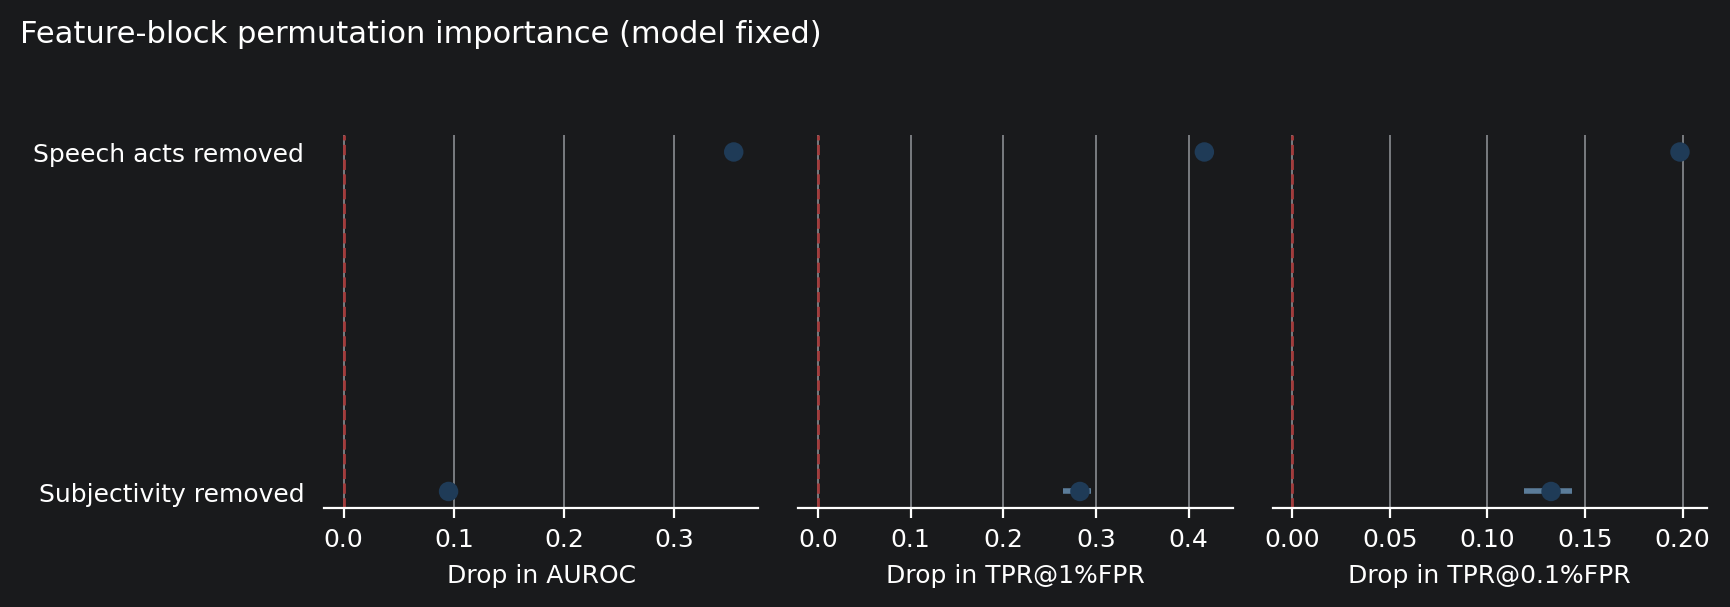

#### Feature blocks — LOFO, all metrics

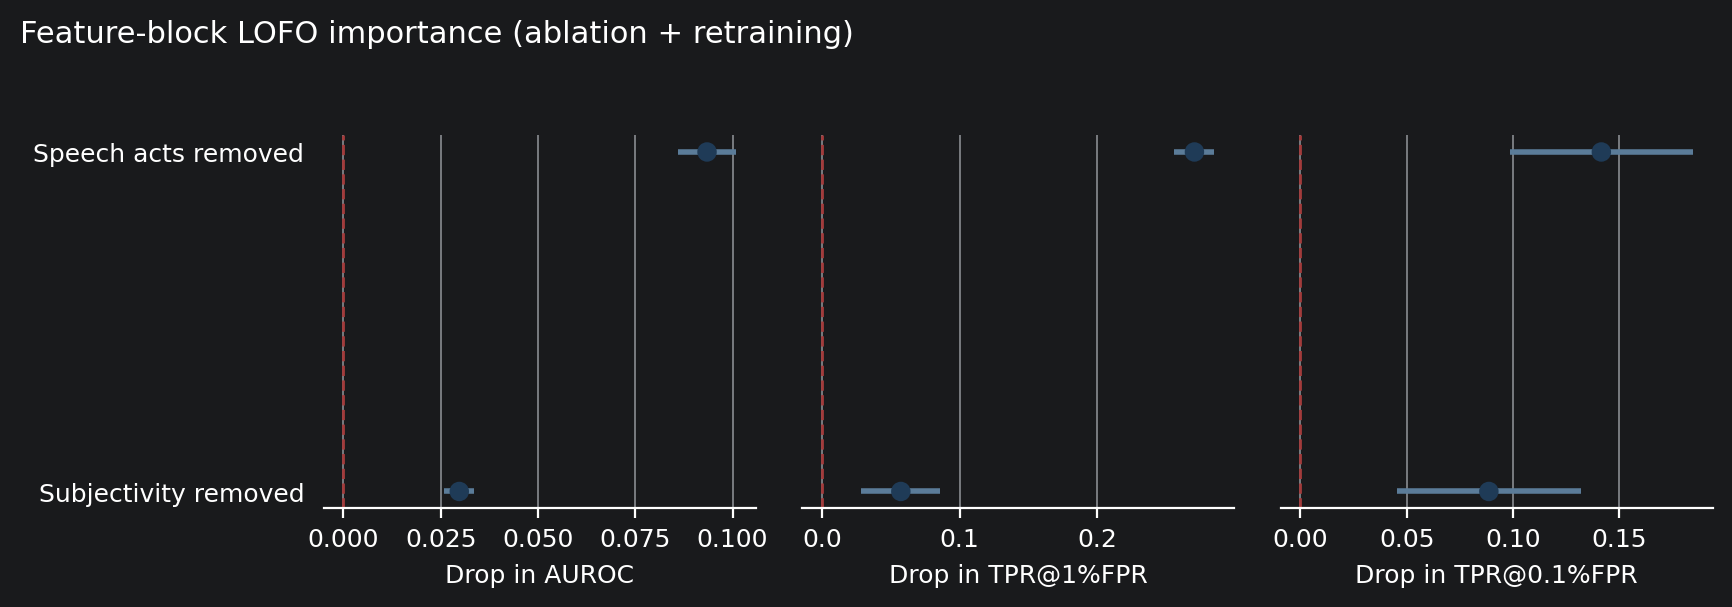

#### Speech acts — indicator permuted, all metrics

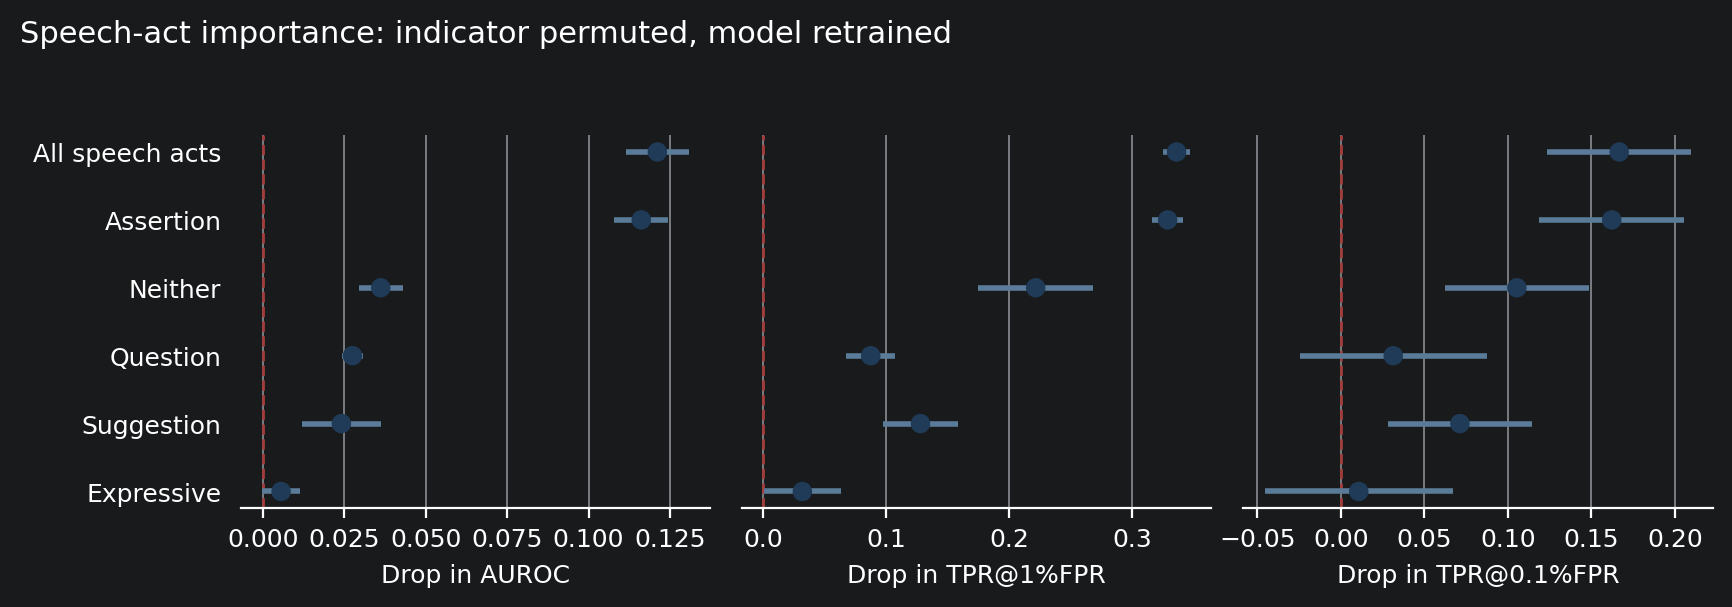

#### Sentence order — all metrics

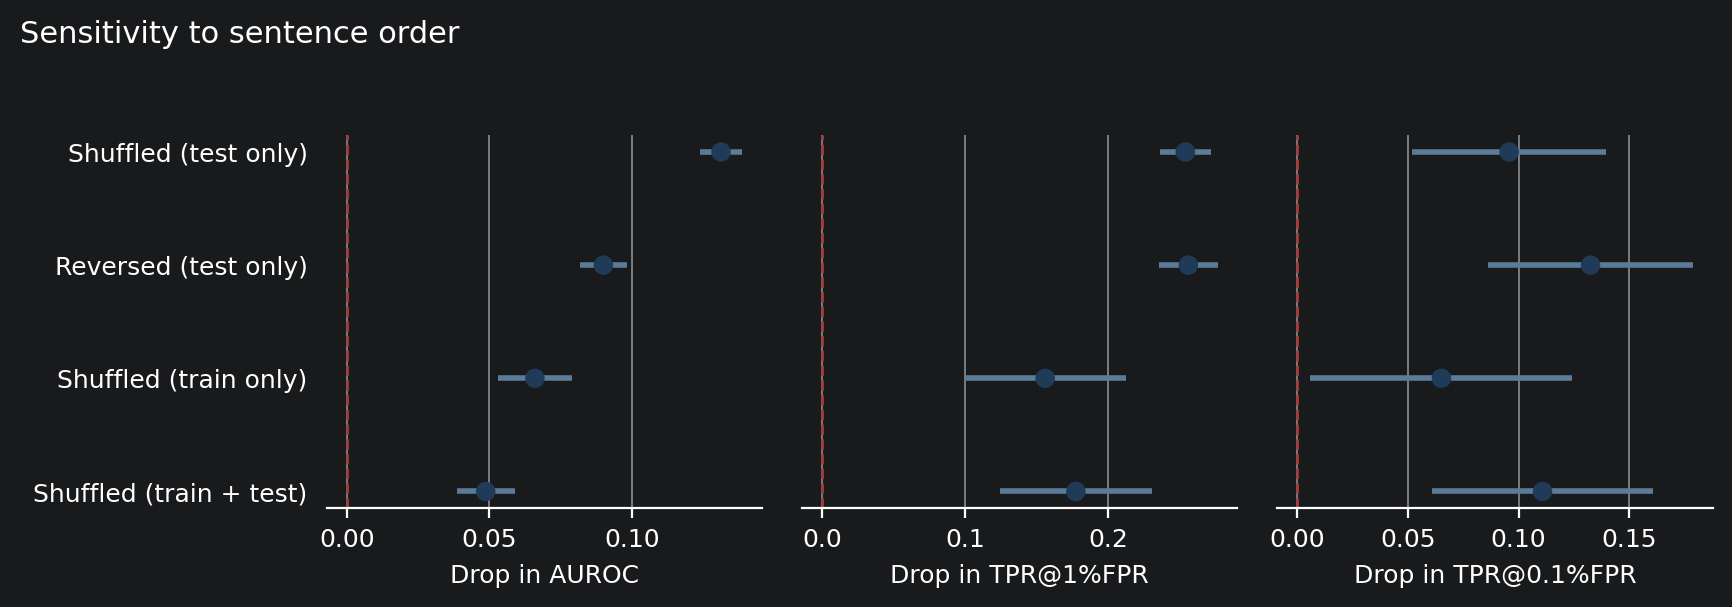

#### Feature blocks — PFI vs LOFO (AUROC)

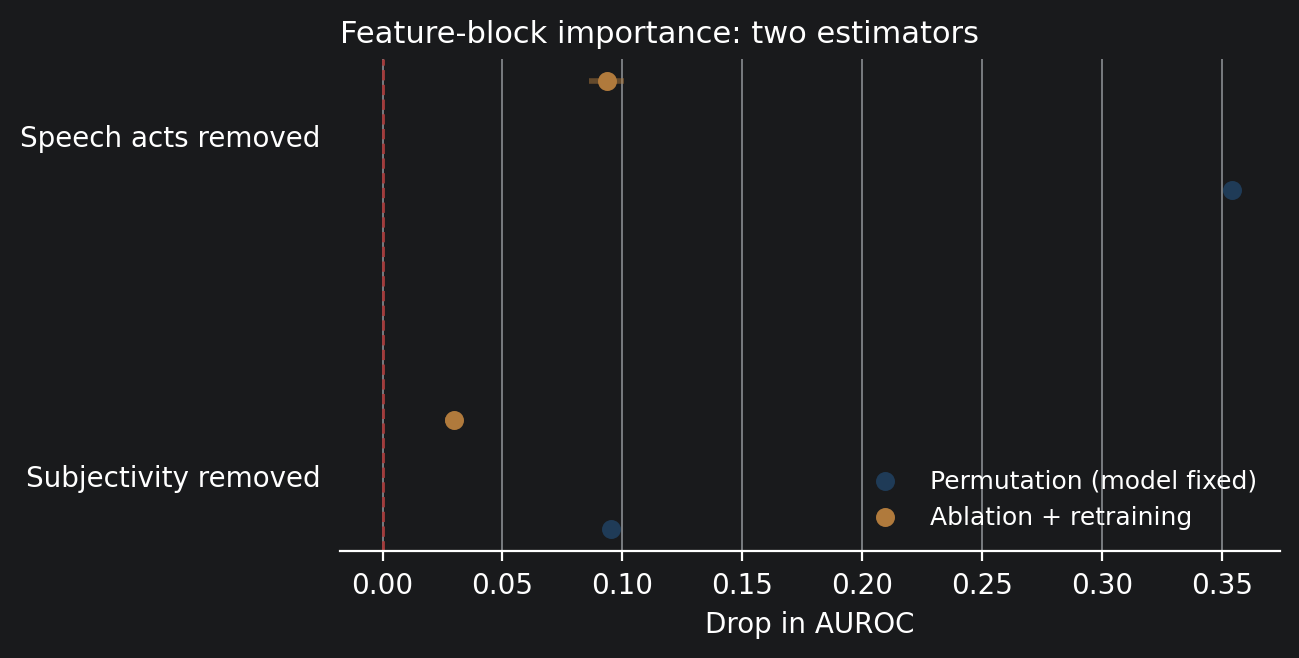

#### Feature blocks — PFI vs LOFO (TPR@1%FPR)

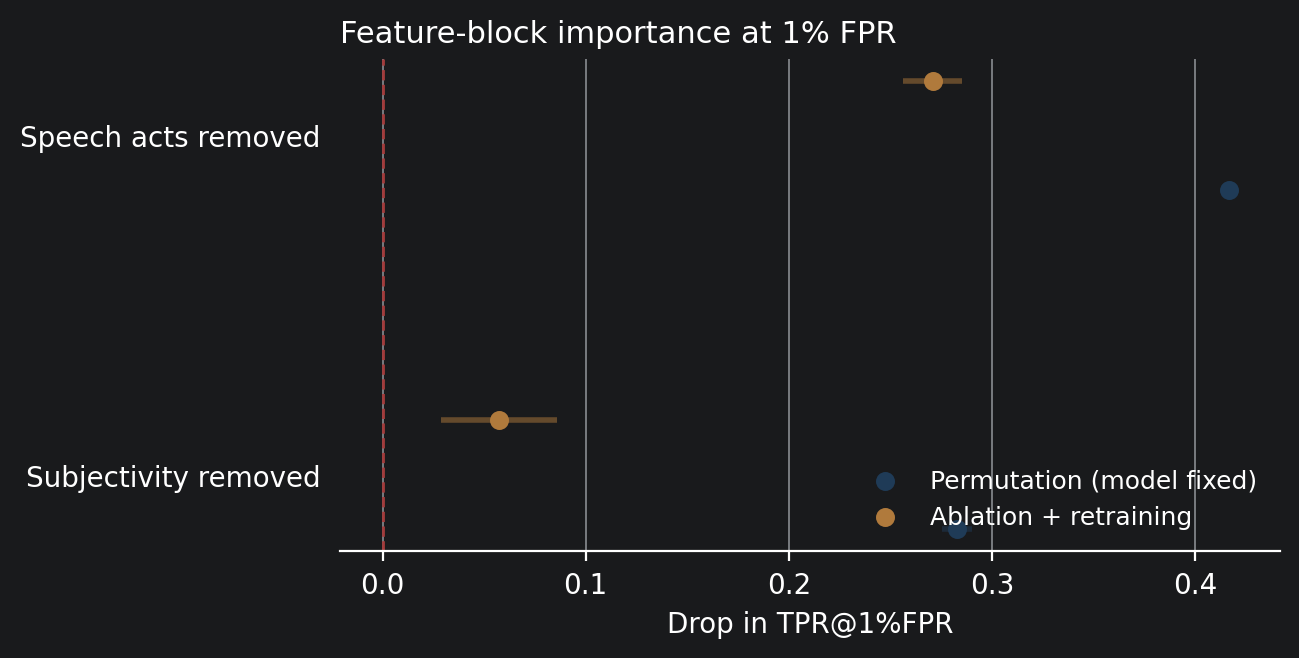

In [35]:
# ═══ cellule 13 ═══ figures
show_all(figures, kind="figure")

In [36]:
show_all(tables, kind="latex")

#### blocks_pfi

% requires: \usepackage{booktabs,amsmath}
\begin{table}[t]
  \centering
  \caption{Permutation importance of feature blocks. Each block is resampled at its own marginal distribution on the test set and the trained model is re-scored without retraining (10 draws). Positive $\Delta$ means destroying the information degrades the metric. Marginal interpretation: a block duplicating information available elsewhere scores low even when predictive. At 0.1\% FPR the test set allows roughly 4.5 false positives, so differences at that operating point are within sampling noise and are reported for completeness only. $^{*}$ marks a difference larger than twice its standard error. Parentheses hold the standard deviation across replicates for values, and the standard error of the difference for $\Delta$.}
  \label{tab:blocks_pfi}
  \begin{tabular}{lrrrrrr}
    \toprule
     & \multicolumn{2}{c}{AUROC} & \multicolumn{2}{c}{TPR@1\%FPR} & \multicolumn{2}{c}{TPR@0.1\%FPR} \\
    \cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7}
    Condition & Value & $\Delta$ & Value & $\Delta$ & Value & $\Delta$ \\
    \midrule
    Speech acts removed & 0.6009 & +0.3540$^{*}$ & 0.0420 & +0.4168$^{*}$ & 0.0097 & +0.1987$^{*}$ \\
    Subjectivity removed & 0.8596 & +0.0953$^{*}$ & 0.1762 & +0.2826$^{*}$ & 0.0758 & +0.1326$^{*}$ \\
    Full model & 0.9549 & -- & 0.4588 & -- & 0.2084 & -- \\
    \bottomrule
  \end{tabular}
\end{table}

#### blocks_lofo

% requires: \usepackage{booktabs,amsmath}
\begin{table}[t]
  \centering
  \caption{Leave-one-feature-out importance of feature blocks. The block is removed from the input tensor and the model retrained (5 seeds, fixed hyperparameters). Conditional interpretation: the figure is what the block adds beyond the remaining ones. \emph{Speech acts removed} leaves a single input column, so its value is a lower bound. At 0.1\% FPR the test set allows roughly 4.5 false positives, so differences at that operating point are within sampling noise and are reported for completeness only. $^{*}$ marks a difference larger than twice its standard error. Parentheses hold the standard deviation across replicates for values, and the standard error of the difference for $\Delta$.}
  \label{tab:blocks_lofo}
  \begin{tabular}{lrrrrrr}
    \toprule
     & \multicolumn{2}{c}{AUROC} & \multicolumn{2}{c}{TPR@1\%FPR} & \multicolumn{2}{c}{TPR@0.1\%FPR} \\
    \cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7}
    Condition & Value & $\Delta$ & Value & $\Delta$ & Value & $\Delta$ \\
    \midrule
    Speech acts removed & 0.8632 & +0.0934$^{*}$ & 0.1983 & +0.2708$^{*}$ & 0.0453 & +0.1417$^{*}$ \\
    Subjectivity removed & 0.9268 & +0.0298$^{*}$ & 0.4118 & +0.0573$^{*}$ & 0.0982 & +0.0887$^{*}$ \\
    Full model & 0.9566 & -- & 0.4691 & -- & 0.1869 & -- \\
    \bottomrule
  \end{tabular}
\end{table}

#### speech_acts_noise

% requires: \usepackage{booktabs,amsmath}
\begin{table}[t]
  \centering
  \caption{Speech-act importance by permutation with retraining. The category indicator is resampled at its own marginal rate in both train and test, so prevalence is preserved and only the association with the label is destroyed; the model is then retrained (5 seeds). Feature count and model capacity are identical across conditions, unlike an ablation. The subjectivity score stays attached to the sentence, so part of the information may leak through that channel and the reported drop is a lower bound. At 0.1\% FPR the test set allows roughly 4.5 false positives, so differences at that operating point are within sampling noise and are reported for completeness only. $^{*}$ marks a difference larger than twice its standard error. Parentheses hold the standard deviation across replicates for values, and the standard error of the difference for $\Delta$.}
  \label{tab:speech_acts_noise}
  \begin{tabular}{lrrrrrr}
    \toprule
     & \multicolumn{2}{c}{AUROC} & \multicolumn{2}{c}{TPR@1\%FPR} & \multicolumn{2}{c}{TPR@0.1\%FPR} \\
    \cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7}
    Condition & Value & $\Delta$ & Value & $\Delta$ & Value & $\Delta$ \\
    \midrule
    All speech acts & 0.8355 & +0.1211$^{*}$ & 0.1326 & +0.3365$^{*}$ & 0.0203 & +0.1667$^{*}$ \\
    Assertion & 0.8404 & +0.1162$^{*}$ & 0.1399 & +0.3292$^{*}$ & 0.0248 & +0.1622$^{*}$ \\
    Neither & 0.9205 & +0.0362$^{*}$ & 0.2474 & +0.2218$^{*}$ & 0.0815 & +0.1054$^{*}$ \\
    Question & 0.9291 & +0.0275$^{*}$ & 0.3817 & +0.0874$^{*}$ & 0.1555 & +0.0314 \\
    Suggestion & 0.9325 & +0.0241$^{*}$ & 0.3412 & +0.1279$^{*}$ & 0.1156 & +0.0714$^{*}$ \\
    Expressive & 0.9511 & +0.0055 & 0.4374 & +0.0317$^{*}$ & 0.1761 & +0.0108 \\
    Full model & 0.9566 & -- & 0.4691 & -- & 0.1869 & -- \\
    \bottomrule
  \end{tabular}
\end{table}

#### sentence_order

% requires: \usepackage{booktabs,amsmath}
\begin{table}[t]
  \centering
  \caption{Sensitivity to sentence order. Shuffling is applied within each review, which preserves composition exactly and destroys only ordering. Only the train+test condition measures order information; the remaining conditions isolate the recency bias induced by the last-hidden-state readout. At 0.1\% FPR the test set allows roughly 4.5 false positives, so differences at that operating point are within sampling noise and are reported for completeness only. $^{*}$ marks a difference larger than twice its standard error. Parentheses hold the standard deviation across replicates for values, and the standard error of the difference for $\Delta$.}
  \label{tab:sentence_order}
  \begin{tabular}{lrrrrrr}
    \toprule
     & \multicolumn{2}{c}{AUROC} & \multicolumn{2}{c}{TPR@1\%FPR} & \multicolumn{2}{c}{TPR@0.1\%FPR} \\
    \cmidrule(lr){2-3} \cmidrule(lr){4-5} \cmidrule(lr){6-7}
    Condition & Value & $\Delta$ & Value & $\Delta$ & Value & $\Delta$ \\
    \midrule
    Shuffled (test only) & 0.8254 & +0.1312$^{*}$ & 0.2153 & +0.2538$^{*}$ & 0.0912 & +0.0957$^{*}$ \\
    Reversed (test only) & 0.8666 & +0.0900$^{*}$ & 0.2132 & +0.2560$^{*}$ & 0.0545 & +0.1325$^{*}$ \\
    Shuffled (train only) & 0.8906 & +0.0660$^{*}$ & 0.3132 & +0.1560$^{*}$ & 0.1218 & +0.0651$^{*}$ \\
    Shuffled (train + test) & 0.9079 & +0.0487$^{*}$ & 0.2917 & +0.1774$^{*}$ & 0.0761 & +0.1108$^{*}$ \\
    Full model & 0.9566 & -- & 0.4691 & -- & 0.1869 & -- \\
    \bottomrule
  \end{tabular}
\end{table}